# 06 · Multi-PLC mode

**Why.** A fault on one machine often stops the next one. Single-PLC files can't show that, because each file holds one controller. Project II added a module that looks at all PLCs at once.

**How it works** (`src/central_logging/multi_plc.py`)
1. All alerts of the plant for one day, from every PLC
2. Keep only alerts that have another alert within **±0.05 s**
3. DBSCAN on the start time, `eps = 0.05 s`, `min_samples = 1`
4. `mixedAlertPlc` marks groups with alerts from more than one PLC
5. `cluster_hour` and `cluster_hour_minute_5min` for hourly and 5-minute views

No text model here: the module only uses time.

**What happened at Volkswagen.** The engineers who reviewed the output found groups that linked PLCs far apart in the plant, which can't affect each other. Time alone was not enough across machines. The generated plant lets me measure that, because it knows which alerts really belong to one cascade and where each PLC sits on the line.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from central_logging import config, plotting
from central_logging.plotting import SERIES, MUTED, TEXT, TEXT_2

plotting.use_style()
pd.set_option("display.max_colwidth", 90)
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
from central_logging import evaluate, multi_plc
from central_logging.generate import alert_day, generate

alerts, truth, plant = generate()
days = sorted(alert_day(alerts).unique())
week2 = days[7:]

parts = []
for day in week2:
    out = multi_plc.cluster(alerts[alert_day(alerts) == day])
    parts.append(out.assign(source=f"Multi_PLC_{day.replace('-', '')}"))
multi = pd.concat(parts, ignore_index=True)
print(f"{len(alerts[alert_day(alerts).isin(week2)]):,} alerts in week 2, {len(multi):,} kept by the ±0.05 s filter")
multi.head()

86,306 alerts in week 2, 7,786 kept by the ±0.05 s filter


,alertId,alertBegin,alertEnd,alertTotalDuration,alertIsBandStop,alertIsTpm,alertCategory,alertText,alertPlc,cluster,mixedAlertPlc,cluster_hour,cluster_hour_minute_5min,source
0,10086029,2024-04-15 00:07:47.779973300+02:00,2024-04-15 00:08:24.119239300+02:00,00:00:36,1,0,technical,MO1 Motor 1 Uebertemperatur,A1FTS01,0,True,0,0_05,Multi_PLC_20240415
1,10086030,2024-04-15 00:07:47.794663400+02:00,2024-04-15 00:07:57.248002300+02:00,00:00:09,0,0,technical,NA8 Nacharbeit 3 angefordert,A1MON01,0,True,0,0_05,Multi_PLC_20240415
2,10086031,2024-04-15 00:07:47.815957100+02:00,2024-04-15 00:07:53.070611600+02:00,00:00:05,0,0,technical,TL8 Toleranz 2 ueberschritten,A1MON01,0,True,0,0_05,Multi_PLC_20240415
3,10086079,2024-04-15 01:02:14.383268200+02:00,2024-04-15 01:02:15.383268200+02:00,00:00:01,1,0,technical,MO1 Motor 1 Uebertemperatur,A1FTS01,1,False,1,1_00,Multi_PLC_20240415
4,10086080,2024-04-15 01:02:14.390186+02:00,2024-04-15 01:02:19.962864700+02:00,00:00:05,0,0,technical,MO1 Motor 1 Uebertemperatur,A1FTS01,1,False,1,1_00,Multi_PLC_20240415


## Mixed-PLC groups: cascade or coincidence?

In [3]:
scores, mixed = evaluate.score_multi(multi, truth, plant)
pd.Series(scores).round(3).to_frame("week 2")

,week 2
alerts_kept,7786.000
clusters,3344.000
mixed_plc_clusters,1858.000
mixed_true_cascade,0.617
mixed_coincidence,0.383
coincidences_far_apart,0.972
true_links_far_apart,0.069


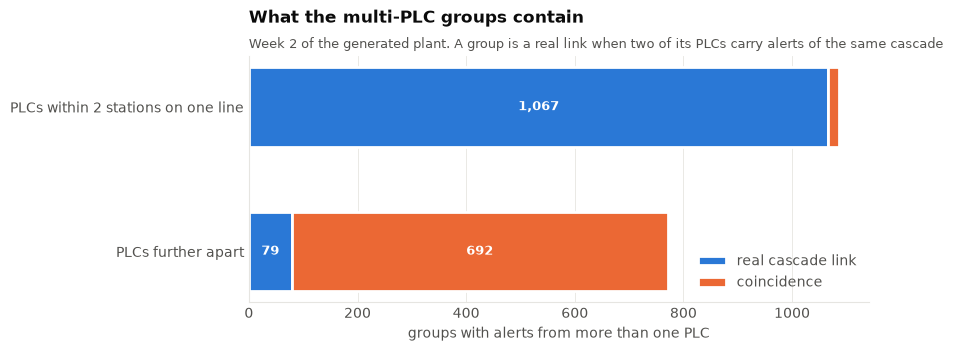

,real cascade link,coincidence
PLCs within 2 stations on one line,1067,20
PLCs further apart,79,692


In [4]:
far = (~mixed["all_neighbours"])
counts = pd.DataFrame({
    "real cascade link": [(mixed.true_link & ~far).sum(), (mixed.true_link & far).sum()],
    "coincidence": [(~mixed.true_link & ~far).sum(), (~mixed.true_link & far).sum()],
}, index=["PLCs within 2 stations on one line", "PLCs further apart"])

fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(2)
for col, color in zip(counts.columns, [SERIES[0], SERIES[1]]):
    bars = ax.barh(counts.index, counts[col], left=left, color=color, height=0.55, label=col,
                   edgecolor="white", linewidth=2)
    for b, v, l in zip(bars, counts[col], left):
        if v > 0.06 * counts.to_numpy().sum(axis=1).max():
            ax.text(l + v / 2, b.get_y() + b.get_height() / 2, f"{v:,}", ha="center", va="center",
                    color="white", fontsize=9, fontweight="bold")
    left += counts[col].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("groups with alerts from more than one PLC")
ax.set_title("What the multi-PLC groups contain")
plotting.subtitle(ax, "Week 2 of the generated plant. A group is a real link when two of its PLCs carry alerts of the same cascade")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "multi_plc_groups.png")
plt.show()
counts

One coincidence: alerts on PLCs of different lines that happened to fire within 0.05 s of each other.

In [5]:
pick = mixed[~mixed.true_link & ~mixed.all_neighbours].iloc[0]["key"]
source, cluster_id = pick.rsplit("|", 1)
example = multi[(multi.source == source) & (multi.cluster == int(cluster_id))]
example = example.merge(plant, on="alertPlc").merge(truth[["alertId", "cascade_id"]], on="alertId")
example[["alertBegin", "alertPlc", "line", "position", "alertText", "cascade_id"]]

,alertBegin,alertPlc,line,position,alertText,cascade_id
0,2024-04-15 09:42:12.707423600+02:00,A2KLB01,A2,3,SY5 Diagnosespeicher 14 voll,-1
1,2024-04-15 09:42:12.729783100+02:00,A1FOE02,A1,14,SE3 Sensor 14 Abgleich erforderlich,-1


## How much of the real cross-PLC chain the window can see
Within a cascade, consecutive alerts on different PLCs are up to 250 ms apart in the generated plant. The ±0.05 s window only catches the fast hops.

In [6]:
t = truth.merge(alerts[["alertId", "alertBegin"]], on="alertId")
t = t[t.cascade_id >= 0].copy()
t["ts"] = pd.to_datetime(t.alertBegin.str[:26])
t = t.sort_values(["cascade_id", "ts"])
prev_plc = t.groupby("cascade_id")["alertPlc"].shift()
gap = t.groupby("cascade_id")["ts"].diff().dt.total_seconds()
hops = gap[(prev_plc.notna()) & (prev_plc != t.alertPlc)]
print(f"{len(hops):,} hops from one PLC to another inside a cascade; "
      f"{(hops <= 0.05).mean():.0%} of them within 0.05 s")

13,383 hops from one PLC to another inside a cascade; 19% of them within 0.05 s


## Takeaway
- Time alone links the right machines most of the time, but every coincidence it adds has no physical reason behind it, and many of them join PLCs on different lines. That is the pattern the engineers at Volkswagen pointed out.
- The fix is not a tighter window. The window already misses most real hops between PLCs. The fix is the plant layout: only allow links between PLCs that are connected in the process.
- Single-PLC mode stays the tool for daily use; multi-PLC mode needs the layout before engineers can act on it.